In [3]:
import jax
import jax.numpy as jnp
import WDM
import WDM_LISAresponse
from WDM_LISAresponse.code.lisa_response.time_domain_response import basis_tensors
import time

key = jax.random.PRNGKey(0)

In [4]:
theta, phi = jnp.ones(1), jnp.ones(1)
basis_tensors(theta, phi)

num_points = 100000

key, subkey = jax.random.split(key)
theta = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=jnp.pi)

key, subkey = jax.random.split(key)
phi = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=2*jnp.pi)

t_start = time.time()
polarisation_basis = basis_tensors(theta, phi)
polarisation_basis.block_until_ready()
t_end = time.time()

print(f"Computed {num_points} basis tensors in {t_end - t_start} seconds")

Computed 100000 basis tensors in 0.005366802215576172 seconds


In [7]:
x = 1.0

x = jnp.asarray(x)

x.shape

()

In [37]:
import jax
import jax.numpy as jnp
from jax import debug as jax_debug

DEBUG = True

def _check(val):
    assert jnp.all(val > 0), "x must be positive"

def _check_something():
    """
    For debugging:
    """
    assert True, "This is a test assertion."

@jax.jit(static_argnames=("debug",))
def f(x, *, debug=True):

    if debug:
        jax_debug.callback(_check, x)  # runs on host, safe in jit
        jax_debug.callback(_check_something)  # runs on host, safe in jit

    return 2*x

f(jnp.array(1.), debug=True)


Array(2., dtype=float32, weak_type=True)

In [30]:
time = jnp.ones((5,))
omega = jnp.ones((8,))

n = jnp.ones((3,9))
#print(n.shape)

light_travel_time = jnp.ones((*time.shape, 6))
print(light_travel_time.shape)

arm_vectors = jnp.ones((*time.shape, 6, 3))
#print(arm_vectors.shape)

n_dot_r = jnp.tensordot(n, arm_vectors, axes=(0, -1))
print(n_dot_r.shape)

arm_vectors = jnp.ones((*time.shape, 6, 3))
#print(arm_vectors.shape)

# 6, *omega.shape, *time.shape,
T =jnp.einsum('a...,...b->b...a', omega, light_travel_time)

T.shape


(5, 6)
(9, 5, 6)


(6, 5, 8)

In [25]:
x = jnp.ones((1,2,3,4))
x.shape[:-1]

(1, 2, 3)

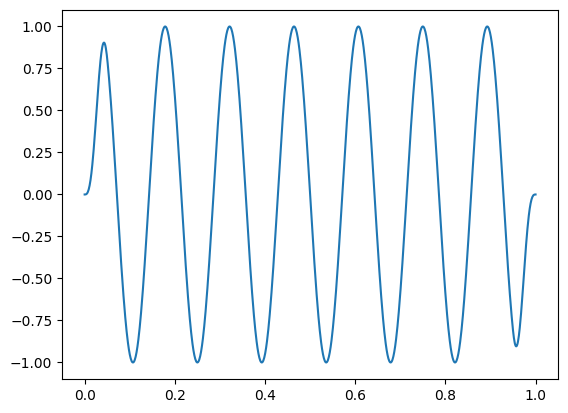

In [50]:
from scipy.signal.windows import tukey
import numpy as np

t = np.linspace(0, 1, 1000)
y = np.sin(2 * np.pi * 7 * t)

w = tukey(len(t), alpha=0.1)

plt.plot(t, y * w)
plt.show()


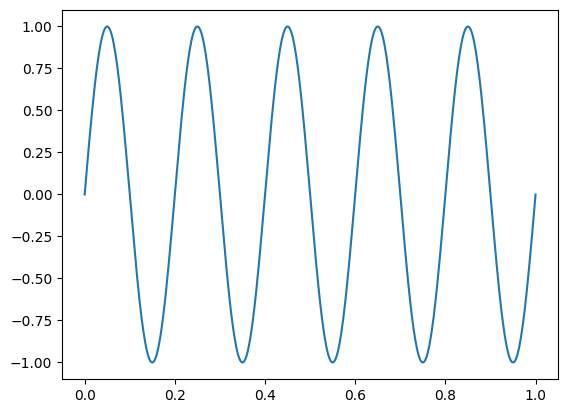

In [51]:
# plot the sine function

import matplotlib.pyplot as plt
import numpy as np
t = np.linspace(0, 1, 500)
y = np.sin(2 * np.pi * 5 * t)
plt.plot(t, y)
plt.show()